# Experimento A/B de los datos: ¿qué se recupera cambiando solo los datos de entrenamiento?

**Avance semana 6 (informe de sprint).** Autores: Gerson Andre Garrido Mansilla y Renzo Elvis
Cerron Tome (Maestría en Ciencias con mención en IA, UNI).

**Contexto.** Se busca segmentar el agua de inundación en imágenes Sentinel-2 de Perú. El caso
realista es una inundación nueva **sin etiquetas peruanas**: solo hay un conjunto etiquetado de otras
regiones (Sen1Floods11) e imágenes de Perú sin etiquetar.

**Qué dijeron las semanas anteriores.**
- Semana 4 (EDA, `notebooks/eda.ipynb`): el suelo seco de Perú (desierto de Sechura) es mucho más
  brillante que el de Sen1Floods11; el agua se parece entre ambos.
- Semana 5 (ingeniería de características, `notebooks/feature_engineering.ipynb`): el cuello de
  botella es ese **cambio de dominio del suelo seco**, no la falta de variables. Los modelos
  entrenados en Sen1Floods11 confunden el desierto con agua.

**Pregunta A/B.** Con el modelo fijo, ¿cuánto mejora el resultado en Perú si **solo** se transforman
las imágenes de entrenamiento de Sen1Floods11 para que se parezcan a las de Perú?

**Métrica central.** IoU de agua agrupado sobre todos los píxeles etiquetados de `peru-dev`:

$$\mathrm{IoU} = \frac{TP}{TP + FP + FN}.$$

Métricas secundarias: precisión y recall del agua, e IoU en `peru-test` (evaluación única). Se
elige IoU y no exactitud porque el agua es minoritaria (EDA): un modelo que no detecta agua tendría
una exactitud alta.

**Qué hace este cuaderno.** Presenta resultados que ya existen en el proyecto. No entrena modelos ni
vuelve a evaluar ninguna partición de prueba. Las cifras se leen de
`notebooks/results/sprint6_results.csv`; cada fila indica de qué entrada de
`docs/EXPERIMENT_LOG.md` o de qué documento proviene.

## 1. Diseño A/B: un solo cambio por variante

**Lo que comparten las tres filas** (`docs/EXPERIMENT_LOG.md` 2026-10-14/15 y 2026-10-15/16):

| Elemento | Valor fijo |
|---|---|
| Modelo | U-Net, codificador ResNet-34 preentrenado en ImageNet, 13 bandas L1C |
| Datos de entrenamiento | Sen1Floods11 `train` (252 recortes, etiquetas manuales) |
| Selección | Mejor época por IoU de agua en Sen1Floods11 `valid` (89 recortes) |
| Configuración | `configs/unet.yaml`: pérdida Dice, AdamW, tasa de aprendizaje 3e-4, lote 8, aumento D4 |
| Parada | Máximo 200 épocas, parada temprana con paciencia 20 |
| Semillas | 0, 1 y 2 |
| Hardware | RunPod RTX 4090, precisión mixta de 16 bits |
| Evaluación | `peru-dev` (174 recortes), nunca usado para entrenar ni para elegir época |

**La única diferencia entre filas** es la transformación aplicada a las imágenes de entrenamiento
(y a las de `valid`, para que la selección vea el mismo estilo de entrada):

| ID | Rol | Qué cambia |
|---|---|---|
| `UNet_s1f11_raw` | ***Baseline*** | Nada: imágenes de Sen1Floods11 tal cual |
| `UNet_s1f11_trHM` | **Var1** | Igualación de histogramas por banda: cada valor se lleva al cuantil equivalente de las imágenes de `peru-train` sin etiquetas (1 001 cuantiles) |
| `UNet_s1f11_trFDA_b0.01` | **Var2** | FDA: la amplitud de Fourier de baja frecuencia (ventana β = 0.01) de cada imagen se reemplaza por la de una imagen de `peru-train` al azar; se conserva la fase |

En los tres casos el modelo final se aplica a las imágenes de Perú **sin modificar**: la transformación
solo existe durante el entrenamiento, así que no hay costo extra en la inferencia.

**Filas de referencia (no son variantes, porque cambian más de una cosa):**
- U-Net entrenada con etiquetas de Perú (`peru-train`, tasa 1e-4, selección en `peru-dev`): cota
  superior de lo que se lograría con etiquetas.
- Umbral de MNDWI = (B03 − B11)/(B03 + B11): ajustado con etiquetas de Sen1Floods11 (semana 5) o
  con Otsu sobre imágenes de Perú sin etiquetas.

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "scripts" / "figures"))
try:
    import style; style.apply(); MCOLOR = style.MODEL
except Exception as e:  # el estilo de las figuras de la tesis es opcional
    print("estilo de tesis no disponible:", e); MCOLOR = {}
%matplotlib inline
pd.set_option("display.precision", 4); pd.set_option("display.max_colwidth", 80)

FIGS = REPO / "docs" / "figs" / "sprint6"; FIGS.mkdir(parents=True, exist_ok=True)
r = pd.read_csv(REPO / "notebooks" / "results" / "sprint6_results.csv", dtype={"seed": str})
bad = r[r.source.isna() | (r.source.str.strip() == "")]
if len(bad):
    raise ValueError(f"filas sin fuente: {bad.index.tolist()}")
test_rows = r[r.split.isin(["peru-test", "peru-2017-test"])]
assert test_rows.source.str.contains("phaseD_test.md|One-time test evaluation").all(), "valores de prueba sin la fuente de la evaluación única"

AB = ["UNet_s1f11_raw", "UNet_s1f11_trHM", "UNet_s1f11_trFDA_b0.01"]
ROLE = {"UNet_s1f11_raw": "Baseline", "UNet_s1f11_trHM": "Var1", "UNet_s1f11_trFDA_b0.01": "Var2"}
COLOR = {"UNet_s1f11_raw": "#6E6E6E", "UNet_s1f11_trHM": "#4477AA", "UNet_s1f11_trFDA_b0.01": "#CCBB44"}
ab = r[r.experiment == "AB"]

def val(eid, split, metric, seed="mean"):
    x = ab[(ab.exp_id == eid) & (ab.split == split) & (ab.metric == metric) & (ab.seed == seed)].value
    return float(x.iloc[0]) if len(x) else np.nan

def save(fig, name):
    fig.savefig(FIGS / f"{name}.png", dpi=200, bbox_inches="tight")
    fig.savefig(FIGS / f"{name}.pdf", bbox_inches="tight")

print(len(r), "valores con fuente;", r.source.nunique(), "documentos de origen distintos")

133 valores con fuente; 29 documentos de origen distintos


## 2. Tabla estándar A/B

Formato de la clase: ID, qué cambió, métrica central, secundarias, costo/latencia y ruta del log.
La media y la desviación estándar de dev se recalculan aquí a partir de las tres semillas y se
comparan con las del registro.

In [2]:
seeds = ab[(ab.split == "peru-dev") & (ab.metric == "iou_water") & ab.seed.isin(["0", "1", "2"])]
seeds = seeds.pivot(index="exp_id", columns="seed", values="value").loc[AB]
check = all(round(seeds.loc[e].mean(), 4) == val(e, "peru-dev", "iou_water") and
            round(seeds.loc[e].std(ddof=1), 4) == val(e, "peru-dev", "iou_water", "std") for e in AB)
print("media y de recalculadas = registro (4 decimales):", check)

def fmt(x, nd=3):
    return "no registrado" if pd.isna(x) else f"{x:.{nd}f}"

COST = {
    "UNet_s1f11_raw": "5.8 s/época; 336–648 s por corrida (RTX 4090, 0.89 USD/h); inferencia sin costo extra",
    "UNet_s1f11_trHM": "+0.11 s/recorte en CPU (≈ 25 s/época con 4 procesos de carga; se usaron 8); inferencia igual",
    "UNet_s1f11_trFDA_b0.01": "+0.26 s/recorte en CPU; inferencia igual",
}
change = ab.drop_duplicates("exp_id").set_index("exp_id")
rows = []
for e in AB:
    s = seeds.loc[e]
    test = val(e, "peru-test", "iou_water")
    rows.append({
        "rol": ROLE[e], "ID": e,
        "qué cambió": {"UNet_s1f11_raw": "nada (imágenes crudas)", "UNet_s1f11_trHM": "histogramas igualados a Perú",
                       "UNet_s1f11_trFDA_b0.01": "amplitud de Fourier de Perú"}[e],
        "IoU dev (media ± de)": f"{s.mean():.4f} ± {s.std(ddof=1):.4f}",
        "semillas 0/1/2": "/".join(f"{v:.4f}" for v in s),
        "precisión dev": fmt(val(e, "peru-dev", "precision")), "recall dev": fmt(val(e, "peru-dev", "recall")),
        "IoU peru-test": "no evaluado (descartado en dev)" if pd.isna(test) else
                         f"{test:.3f} [{val(e, 'peru-test', 'iou_water', 'ci_low'):.3f}, {val(e, 'peru-test', 'iou_water', 'ci_high'):.3f}]",
        "costo / latencia": COST[e],
        "log": change.loc[e, "run_dir"],
    })
tab = pd.DataFrame(rows).set_index("rol")
tab.to_csv(FIGS / "tabla_ab.csv")
display(tab)

ref = ab[(ab.role == "reference") & (ab.seed.isin(["mean", "single"]))][["exp_id", "change", "train_data", "split", "value"]]
ref["change"] = ref.change.map({"non-learned threshold (no Peru labels)": "umbral sin aprendizaje; etiquetas de Sen1Floods11 (semana 5, 1/4 de los píxeles)",
                                "non-learned threshold (no labels)": "umbral sin aprendizaje, sin etiquetas",
                                "different training data (peru-train labels) and LR 1e-4; selection on peru-dev": "usa etiquetas de Perú, tasa 1e-4 y selección en peru-dev (cota superior)"})
ref["train_data"] = ref.train_data.replace({"none": "ninguna"})
ref = ref.rename(columns={"exp_id": "referencia", "change": "por qué no es una variante", "train_data": "etiquetas usadas", "split": "partición", "value": "IoU de agua"})
ref.to_csv(FIGS / "tabla_ab_referencias.csv", index=False)
display(ref.reset_index(drop=True))

media y de recalculadas = registro (4 decimales): True


,ID,qué cambió,IoU dev (media ± de),semillas 0/1/2,precisión dev,recall dev,IoU peru-test,costo / latencia,log
rol,,,,,,,,,
Baseline,UNet_s1f11_raw,nada (imágenes crudas),0.8364 ± 0.0224,0.8433/0.8545/0.8114,0.848,0.985,"0.576 [0.467, 0.669]","5.8 s/época; 336–648 s por corrida (RTX 4090, 0.89 USD/h); inferencia sin co...",outputs/s1f11_src_unet/unet/lightning_logs/seed<s>
Var1,UNet_s1f11_trHM,histogramas igualados a Perú,0.9118 ± 0.0026,0.9148/0.9098/0.9108,0.962,0.946,"0.798 [0.704, 0.865]",+0.11 s/recorte en CPU (≈ 25 s/época con 4 procesos de carga; se usaron 8); ...,outputs/s1f11_trhm_unet/unet/lightning_logs/seed<s>
Var2,UNet_s1f11_trFDA_b0.01,amplitud de Fourier de Perú,0.6151 ± 0.1122,0.7251/0.5009/0.6193,no registrado,no registrado,no evaluado (descartado en dev),+0.26 s/recorte en CPU; inferencia igual,outputs/s1f11_trfda_unet/unet/lightning_logs/seed<s>


,referencia,por qué no es una variante,etiquetas usadas,partición,IoU de agua
0,MNDWI_s1f11_t0.15,"umbral sin aprendizaje; etiquetas de Sen1Floods11 (semana 5, 1/4 de los píxe...",sen1floods11-train,peru-dev,0.8358
1,MNDWI_pool_otsu,"umbral sin aprendizaje, sin etiquetas",ninguna,peru-dev,0.5718
2,UNet_peru,"usa etiquetas de Perú, tasa 1e-4 y selección en peru-dev (cota superior)",peru-train,peru-dev,0.9415
3,UNet_peru,"usa etiquetas de Perú, tasa 1e-4 y selección en peru-dev (cota superior)",peru-train,peru-test,0.8280


## 3. Gráfico único

Izquierda: IoU de agua en `peru-dev` por semilla (puntos) y media ± desviación estándar (barra), con
la cota superior de la U-Net entrenada con etiquetas de Perú (línea discontinua). Derecha: precisión
y recall de agua en dev. La clase sugiere una curva PR para clasificación, pero requiere los logits de
cada modelo, que no están en esta máquina (`outputs/` no se versiona).

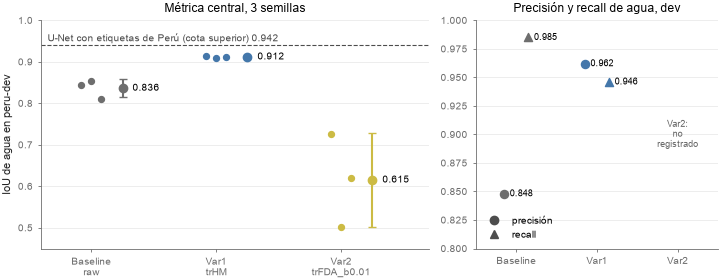

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(7.4, 3.0), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axs[0]
for i, e in enumerate(AB):
    v = seeds.loc[e].values
    ax.scatter(np.full(3, i) + np.array([-0.08, 0, 0.08]), v, color=COLOR[e], s=18, zorder=3)
    ax.errorbar(i + 0.25, v.mean(), yerr=v.std(ddof=1), fmt="o", color=COLOR[e], ms=6, capsize=3, zorder=3)
    ax.text(i + 0.33, v.mean(), f"{v.mean():.3f}", va="center", fontsize=7)
up = val("UNet_peru", "peru-dev", "iou_water")
ax.axhline(up, ls="--", lw=0.8, color="0.3")
ax.text(-0.35, up + 0.008, f"U-Net con etiquetas de Perú (cota superior) {up:.3f}", fontsize=7, color="0.3")
ax.set_xticks(range(3), [f"{ROLE[e]}\n{e.replace('UNet_s1f11_', '')}" for e in AB])
ax.set_xlim(-0.4, 2.7); ax.set_ylim(0.45, 1.0); ax.grid(axis="y")
ax.set_ylabel("IoU de agua en peru-dev"); ax.set_title("Métrica central, 3 semillas")
ax = axs[1]
for j, (m, mk, lab) in enumerate([("precision", "o", "precisión"), ("recall", "^", "recall")]):
    for i, e in enumerate(AB[:2]):
        v = val(e, "peru-dev", m)
        ax.scatter(i + (j - 0.5) * 0.3, v, marker=mk, color=COLOR[e], s=34, zorder=3)
        ax.text(i + (j - 0.5) * 0.3 + 0.07, v, f"{v:.3f}", va="center", fontsize=6.5)
ax.text(2, 0.9, "Var2:\nno\nregistrado", ha="center", va="center", fontsize=6.5, color="0.4")
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color="0.3", label="precisión"),
                   plt.Line2D([], [], marker="^", ls="", color="0.3", label="recall")], loc="lower left")
ax.set_xticks(range(3), ["Baseline", "Var1", "Var2"]); ax.set_xlim(-0.5, 2.5); ax.set_ylim(0.8, 1.0); ax.grid(axis="y")
ax.set_title("Precisión y recall de agua, dev")
plt.tight_layout(); save(fig, "fig_ab_datos"); plt.show()

## 4. Validación

- **Partición agrupada, sin fuga.** `peru-dev` y `peru-test` salen de bloques espaciales de unos 20 km,
  con una franja de *buffer* descartada (192 recortes); una ubicación nunca aparece en dos particiones
  (EDA, semana 4). Sen1Floods11 usa sus particiones oficiales, sin volver a partir.
- **Divide primero, transforma después.** Los cuantiles de la igualación de histogramas y las
  amplitudes de FDA se calculan **solo** con imágenes de `peru-train`, sin leer sus etiquetas. Nunca
  se usan imágenes de `peru-dev` ni de prueba para ajustar la transformación.
- **Semillas y particiones fijas.** Las tres filas usan las semillas 0, 1 y 2 y las mismas
  particiones.
- **Selección sin dev.** La mejor época se elige en Sen1Floods11 `valid`; `peru-dev` solo se usa para
  comparar las variantes.
- **Prueba una sola vez.** `peru-test` y `peru-2017-test` se evaluaron el 2026-10-16, desde
  configuraciones congeladas con el hash de cada checkpoint (`configs/frozen.yaml`).
- **¿Por qué no hay validación cruzada K-fold?** Las reglas del proyecto prohíben volver a partir
  Sen1Floods11, y un K-fold sobre bloques de Perú obligaría a reentrenar cada fila K veces en GPU
  alquilada. En su lugar se reportan 3 semillas e intervalos *bootstrap* por recortes en prueba.

**Ruido entre corridas.** Repetir la semilla 0 del *baseline* con la misma configuración dio una
diferencia de 0.017 de IoU en `valid` (no determinismo de cuDNN y precisión mixta). Las diferencias
del experimento (+0.075 y −0.221 en dev) son mucho mayores.

**Diferencia operativa (no es un cambio de los datos).** Var1 y Var2 se entrenaron con 8 procesos de
carga de datos en lugar de 4, para que la transformación en CPU no frenara el entrenamiento. Esto
cambia el orden aleatorio de las rotaciones y reflejos, no los datos ni el modelo.

## 5. Decisión: adoptar o descartar

La regla se fijó **antes** de ver los resultados: elegir entre HM y FDA por el IoU en dev de la
semilla 0 (`docs/METHODS_NOTES.md`, 2026-10-15). Solo la variante elegida pasó a la evaluación única
en prueba.

In [4]:
dec = pd.DataFrame({
    "IoU dev semilla 0 (regla)": [val("UNet_s1f11_trHM", "peru-dev", "hm_vs_fda_rule_seed0", "0"), val("UNet_s1f11_trFDA_b0.01", "peru-dev", "hm_vs_fda_rule_seed0", "0")],
    "IoU dev 3 semillas": [f"{seeds.loc[e].mean():.3f} ± {seeds.loc[e].std(ddof=1):.3f}" for e in AB[1:]],
    "decisión": ["ADOPTAR", "DESCARTAR"],
}, index=["Var1 trHM", "Var2 trFDA"])
display(dec)
d = ab[(ab.exp_id == "UNet_s1f11_trHM") & ab.metric.str.startswith("diff_vs")].copy()
d["value"] = d.value.astype(float)
d = d.pivot_table(index=["split", "metric"], columns="seed", values="value")
d = d.rename(columns={"mean": "diferencia", "ci_low": "IC 95 % inf.", "ci_high": "IC 95 % sup."})[["diferencia", "IC 95 % inf.", "IC 95 % sup."]]
LBL = {("peru-test", "diff_vs_baseline"): "Var1 − baseline, peru-test",
       ("peru-test", "diff_vs_peru_trained_unet"): "Var1 − U-Net con etiquetas de Perú, peru-test",
       ("peru-2017-test", "diff_vs_baseline"): "Var1 − baseline, peru-2017-test"}
d.index = [LBL[i] for i in d.index]
d.to_csv(FIGS / "tabla_ab_prueba.csv"); display(d)
gain = seeds.loc["UNet_s1f11_trHM"].values - seeds.loc["UNet_s1f11_raw"].values
print("Var1 − baseline en dev, por semilla:", np.round(gain, 4))

,IoU dev semilla 0 (regla),IoU dev 3 semillas,decisión
Var1 trHM,0.9148,0.912 ± 0.003,ADOPTAR
Var2 trFDA,0.7251,0.615 ± 0.112,DESCARTAR


seed,diferencia,IC 95 % inf.,IC 95 % sup.
"Var1 − baseline, peru-2017-test",-0.064,-0.083,-0.046
"Var1 − baseline, peru-test",0.222,0.132,0.309
"Var1 − U-Net con etiquetas de Perú, peru-test",-0.030,-0.048,-0.013


Var1 − baseline en dev, por semilla: [0.0715 0.0553 0.0994]


**Var1 (igualación de histogramas): se adopta.**
- Mejora la métrica central en todas las semillas (+0.072, +0.055, +0.100 en dev) y reduce mucho la
  variación entre semillas (desviación estándar 0.003 frente a 0.022).
- La mejora viene de la precisión (0.848 → 0.962): elimina la mayoría de los falsos positivos del
  desierto, el error que identificaron las semanas 4 y 5. Cuesta algo de recall (0.985 → 0.946).
- En `peru-test` se confirma: +0.222 [0.132, 0.309] sobre el *baseline*. Queda 0.030 [0.013, 0.048]
  por debajo de la U-Net entrenada con etiquetas de Perú, sin usar ninguna etiqueta peruana.
- Costo: solo en el entrenamiento (0.11 s por recorte en CPU); la inferencia no cambia. Es viable.

**Var2 (FDA): se descarta.** Baja a 0.615 ± 0.112 en dev, con mucha variación entre semillas. No se
evaluó en prueba, como manda el protocolo. Es además la variante más costosa (0.26 s por recorte).

**Advertencia sobre otro evento.** En `peru-2017-test` el orden se invierte: Var1 queda 0.064 [0.046,
0.083] por debajo del *baseline*. Las etiquetas de 2017 solo definen suelo seco donde MNDWI ≤ 0, así
que miden sobre todo el recall del agua clara, justo lo que Var1 sacrifica para quitar falsos
positivos (`docs/phaseD_test.md`). La decisión vale para el evento de 2023.

## 6. Verificación con los resultados originales (si están disponibles)

`outputs/` no forma parte del repositorio. Si está presente, se comparan los IoU por semilla de la
tabla con `outputs/phaseD/dev_table_runs.csv`, calculado desde los logits guardados.

In [5]:
src = REPO / "outputs" / "phaseD" / "dev_table_runs.csv"
if src.exists():
    o = pd.read_csv(src); o["seed"] = o.seed.astype(str).str.replace("seed", "")
    reg = {"UNet_s1f11_raw": "s1f11_src", "UNet_s1f11_trHM": "trhm", "UNet_s1f11_trFDA_b0.01": "trfda"}
    mine = seeds.stack().rename("value").reset_index()
    mine["regime"] = mine.exp_id.map(reg); mine["model"] = "unet"
    m = mine.merge(o[["regime", "model", "seed", "iou"]], on=["regime", "model", "seed"], how="left")
    m["dif"] = (m.value - m.iou).abs(); display(m)
    print("diferencias > 1e-4:", int((m.dif > 1e-4).sum()), "| filas sin par:", int(m.iou.isna().sum()))
else:
    print("outputs/ no está en esta máquina: se usa solo la tabla con fuentes (notebooks/results/sprint6_results.csv).")

outputs/ no está en esta máquina: se usa solo la tabla con fuentes (notebooks/results/sprint6_results.csv).


## 7. Conclusiones

1. **Cambiar solo los datos de entrenamiento basta para recuperar casi todo el desempeño sin
   etiquetas peruanas.** Igualar los histogramas de Sen1Floods11 a imágenes de Perú sin etiquetar sube
   el IoU de 0.836 a 0.912 en dev y de 0.576 a 0.798 en prueba.
2. **Lo que se corrige es el suelo seco.** La precisión pasa de 0.848 a 0.962: es la confirmación
   experimental del diagnóstico de las semanas 4 y 5.
3. **No toda transformación de los datos sirve.** FDA, que también acerca el estilo de las imágenes,
   empeora el resultado y lo vuelve inestable.
4. **Se adopta Var1** para el evento de 2023. Para otros eventos hay que vigilar la pérdida de agua
   tenue (prueba de 2017).

**Limitaciones.**
- Una sola partición espacial y 3 semillas; sin validación cruzada.
- En prueba solo hay valores agregados (media, de, IC) y diferencias pareadas.
- Var2 no tiene precisión ni recall registrados en los documentos versionados.
- Los umbrales de MNDWI se evaluaron sobre 1/4 de los píxeles de dev.

---

## Anexo: comparación de modelos con etiquetas de Perú (contexto)

Este anexo no es parte del A/B de la semana 6: cambia el modelo, no los datos. Los tres modelos se
entrenaron con `peru-train` (etiquetas de Perú), con la configuración oficial de cada uno, 3 semillas,
y selección en `peru-dev` (`docs/EXPERIMENT_LOG.md`, 2026-10-13/14).

,modelo,IoU dev (media ± de),IoU peru-test [IC 95 %],precisión / recall peru-test,IoU peru-2017-test (101)
UNet_peru,U-Net (ResNet-34),0.9415 ± 0.0019,"0.828 [0.732, 0.895]",0.966 / 0.853,0.878
TerraMind_peru,TerraMind v1-B,0.9265 ± 0.0025,"0.815 [0.718, 0.885]",0.960 / 0.843,0.892
Prithvi_peru,Prithvi-EO-2.0 300M,0.9218 ± 0.0007,"0.824 [0.731, 0.890]",0.966 / 0.850,0.878


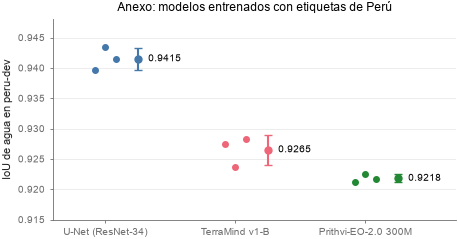

In [6]:
an = r[r.experiment == "annex"]
ORDER = ["UNet_peru", "TerraMind_peru", "Prithvi_peru"]
NAME = {"UNet_peru": "U-Net (ResNet-34)", "TerraMind_peru": "TerraMind v1-B", "Prithvi_peru": "Prithvi-EO-2.0 300M"}
def aval(eid, split, metric, seed="mean"):
    x = an[(an.exp_id == eid) & (an.split == split) & (an.metric == metric) & (an.seed == seed)].value
    return float(x.iloc[0]) if len(x) else np.nan
aseeds = an[(an.split == "peru-dev") & (an.metric == "iou_water") & an.seed.isin(["0", "1", "2"])].pivot(index="exp_id", columns="seed", values="value").loc[ORDER]
atab = pd.DataFrame({
    "modelo": [NAME[e] for e in ORDER],
    "IoU dev (media ± de)": [f"{aseeds.loc[e].mean():.4f} ± {aseeds.loc[e].std(ddof=1):.4f}" for e in ORDER],
    "IoU peru-test [IC 95 %]": [f"{aval(e, 'peru-test', 'iou_water'):.3f} [{aval(e, 'peru-test', 'iou_water', 'ci_low'):.3f}, {aval(e, 'peru-test', 'iou_water', 'ci_high'):.3f}]" for e in ORDER],
    "precisión / recall peru-test": [f"{aval(e, 'peru-test', 'precision'):.3f} / {aval(e, 'peru-test', 'recall'):.3f}" for e in ORDER],
    "IoU peru-2017-test (101)": [aval(e, "peru-2017-test", "iou_water_101") for e in ORDER],
}, index=ORDER)
atab.to_csv(FIGS / "tabla_anexo_modelos.csv"); display(atab)

fig, ax = plt.subplots(figsize=(5.2, 2.6))
KEY = {"UNet_peru": "unet", "TerraMind_peru": "terramind_v1_base", "Prithvi_peru": "prithvi_eo_v2_300"}
for i, e in enumerate(ORDER):
    v = aseeds.loc[e].values; c = MCOLOR.get(KEY[e], f"C{i}")
    ax.scatter(np.full(3, i) + np.array([-0.08, 0, 0.08]), v, color=c, s=16, zorder=3)
    ax.errorbar(i + 0.25, v.mean(), yerr=v.std(ddof=1), fmt="o", color=c, ms=5, capsize=3, zorder=3)
    ax.text(i + 0.33, v.mean(), f"{v.mean():.4f}", va="center", fontsize=7)
ax.set_xticks(range(3), [NAME[e] for e in ORDER]); ax.set_xlim(-0.4, 2.7); ax.set_ylim(0.915, 0.948)
ax.set_ylabel("IoU de agua en peru-dev"); ax.grid(axis="y"); ax.set_title("Anexo: modelos entrenados con etiquetas de Perú")
save(fig, "fig_anexo_modelos"); plt.show()

**Lectura del anexo.**
- En dev, la U-Net (0.9415) supera a TerraMind (0.9265) y a Prithvi (0.9218). El 73 % y el 86 % de esa
  ventaja está en la franja de 1 px del borde de la etiqueta (`docs/METHODS_NOTES.md`, 2026-10-14).
- En `peru-test` las tres medias quedan a menos de 0.014 entre sí, con IC solapados, y no se
  calcularon diferencias pareadas entre ellas: no se afirma un orden.
- Con etiquetas del mismo evento, el modelo importa poco. Con un umbral de MNDWI ajustado en
  `peru-train` ya se llega a 0.924 en dev (semana 5). Por eso el experimento de esta semana se centra
  en los datos.